# Random Forest Research Baseline

Random Forest is used as a conventional tree-based baseline for comparison. This notebook evaluates agreement with the project's **reference-derived FAO-56 ETc estimate**, not field-observed CWR or measured farm water use. Training is permitted only if the repository target metadata, target assessment, and `ETc = ET0 × Kc` panel values pass the readiness gate.

## 1. Objective

Fit and evaluate an offline one-day-ahead Random Forest baseline using only the previous observation day's approved reduced-input features and chronological partitions. This experiment does not propose Random Forest as the project's novelty.

## 2. Project Safety Rules

- Training data is restricted to `datasets/processed/cwr_baseline_panel.parquet`.
- `crop_dataset.csv`, `crop_water_data.csv`, and `data_season.csv` are not target evidence and are never loaded as training data.
- The target, ET0, Kc, target-derived water-balance variables, measured radiation, and wind are excluded from predictors.
- The target is reference-derived `etc_mm_day`, not field-observed CWR. If repository validation fails, training stops with an explicit blocked message.
- Every feature is lagged one observation day within its crop/sowing-date cohort. Current-day rainfall and other same-day observations are not used to predict that day's target.
- Artifacts are written only to `artifacts/research_baselines/random_forest/`. No production registry, active pointer, API, frontend, or irrigation logic is changed.

## 3. Load Approved Data

In [28]:
import importlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (candidate for candidate in (cwd, *cwd.parents)
     if (candidate / 'ml').is_dir() and (candidate / 'datasets').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook from within the Jalachakra project.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ml import random_forest_baseline as rf
rf = importlib.reload(rf)
from ml import target_builder as tb

panel = rf.load_approved_panel(PROJECT_ROOT)
active_metadata_path = PROJECT_ROOT / rf.TARGET_METADATA_RELATIVE_PATH
target_metadata = json.loads(active_metadata_path.read_text(encoding='utf-8'))['target_definition']
assessment_path = PROJECT_ROOT / rf.TARGET_ASSESSMENT_RELATIVE_PATH
assessment_text = assessment_path.read_text(encoding='utf-8')
print(f'Approved panel: {rf.APPROVED_PANEL_RELATIVE_PATH.as_posix()}')
print(f'Rows: {len(panel):,}; columns: {len(panel.columns)}')
print(f"Dates: {pd.to_datetime(panel['date']).min().date()} to {pd.to_datetime(panel['date']).max().date()}")
print(f"Target candidate: {target_metadata.get('name')} ({target_metadata.get('unit')})")
print('Target provenance:', target_metadata.get('provenance_class'))
print('Field observed:', target_metadata.get('is_field_observed'))

Approved panel: datasets/processed/cwr_baseline_panel.parquet
Rows: 158,118; columns: 35
Dates: 2018-01-01 to 2024-12-29
Target candidate: etc_mm_day (mm/day)
Target provenance: reference_derived
Field observed: False


## 4. Target Readiness Check

The gate verifies the approved target definition, explicit reference-derived/non-field-observed status, target assessment, finite non-negative values, and equality of the panel target to `ET0 × Kc`. This is an ETc reference-estimation experiment, not validation against observed CWR.

In [29]:
TARGET_READY, target_readiness_reasons = rf.assess_target_readiness(
    target_metadata, panel, assessment_text
)
if TARGET_READY:
    print('Target readiness passed for reference-derived ETc only.')
    print('This target is NOT field-observed CWR or measured farm water use.')
else:
    display(Markdown('**Random Forest training blocked:**\nCWR target is not yet scientifically validated.'))
    for reason in target_readiness_reasons:
        print('-', reason)
    print('Metrics unavailable because target validation did not pass.')

Target readiness passed for reference-derived ETc only.
This target is NOT field-observed CWR or measured farm water use.


## 5. Feature Selection

In [30]:
if TARGET_READY:
    features = rf.select_features(panel)
    print('FINAL RF FEATURES:')
    print(features)
else:
    features = []

FINAL RF FEATURES:
['t2m', 't2m_min', 't2m_max', 'rh2m', 'temp_range_c', 'rainfall_mm', 'rain_sum_7d_mm', 'rain_sum_30d_mm', 'days_since_rain', 'day_of_year', 'doy_sin', 'doy_cos', 'month', 'days_after_sowing', 'crop', 'growth_stage']


## 6. Leakage Check

The approved reduced-input task excludes same-day ET0 and Kc because they reconstruct the target. It also excludes ETc itself, radiation, wind, effective rainfall, and post-balance irrigation/depletion outputs. Before splitting or fitting, every selected feature is shifted one observation day within its crop/sowing-date cohort; target-day weather/rainfall cannot leak into that day's estimate.

In [31]:
leakage_audit = pd.DataFrame(rf.LEAKAGE_AUDIT, columns=['Feature', 'Status', 'Reason'])
display(leakage_audit)
if TARGET_READY:
    tb.assert_no_leakage(features, 'reduced_input')
    assert tb.TARGET_COLUMN not in features
    assert set(features).issubset(panel.columns)
    assert 'date' not in features, 'Observation date is used for partitioning, not as a predictor.'
    print('Leakage check passed; no future or post-event features are selected.')

,Feature,Status,Reason
0,et0_mm_day,EXCLUDED,Direct FAO-56 reference input; target is ET0 ×...
1,kc,EXCLUDED,Direct crop-coefficient multiplier in the target.
2,etc_mm_day,EXCLUDED,The target itself must never appear in X.
3,allsky_sfc_sw_dwn,EXCLUDED,Withheld from the approved reduced-input task.
4,ws2m,EXCLUDED,Withheld from the approved reduced-input task.
5,rn_mj_m2_day and other ET0-derived terms,EXCLUDED,Downstream of FAO-56 ET0.
6,effective_rainfall_mm,EXCLUDED,"Water-balance output, not a permitted input."
7,net_irrigation_mm and gross_irrigation_mm,EXCLUDED,Derived after the crop-water calculation.
8,"root_zone_depletion_mm, depletion_fraction, ir...",EXCLUDED,Post-event irrigation-state outputs.
9,selected reduced-input predictors,ALLOWED (LAGGED 1 DAY),Only the prior observation day within the same...


Leakage check passed; no future or post-event features are selected.


## 7. Preprocessing

The sklearn `Pipeline` contains a `ColumnTransformer`: median imputation for numeric features and most-frequent imputation plus one-hot encoding for categoricals. Preprocessing is fitted only by `pipeline.fit(X_train, y_train)`.

In [32]:
if TARGET_READY:
    pipeline = rf.make_pipeline(features)
    print(pipeline)
else:
    pipeline = None

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['t2m', 't2m_min', 't2m_max',
                                                   'rh2m', 'temp_range_c',
                                                   'rainfall_mm',
                                                   'rain_sum_7d_mm',
                                                   'rain_sum_30d_mm',
                                                   'days_since_rain',
                                                   'day_of_year', 'doy_sin',
                                                   'doy_cos', 'month',
                                                   'days_after_sowing']),
                                                 ('cat',
                      

## 8. Chronological Train/Validation/Test Split

In [33]:
if TARGET_READY:
    aligned_panel = rf.build_one_day_ahead_panel(panel, features)
    dates = pd.to_datetime(aligned_panel['date'])
    split = tb.chronological_split(dates)
    partitions = {name: aligned_panel.loc[split[name]].copy() for name in ('train', 'validation', 'test')}
    split_summary = {
        'strategy': 'chronological split on target date; one-day-ahead features; 60% train, 20% validation, 20% test',
        'train_rows': len(partitions['train']),
        'validation_rows': len(partitions['validation']),
        'test_rows': len(partitions['test']),
        'train_start': str(pd.to_datetime(partitions['train']['date']).min().date()),
        'train_end': str(pd.to_datetime(partitions['train']['date']).max().date()),
        'validation_start': str(pd.to_datetime(partitions['validation']['date']).min().date()),
        'validation_end': str(pd.to_datetime(partitions['validation']['date']).max().date()),
        'test_start': str(pd.to_datetime(partitions['test']['date']).min().date()),
        'test_end': str(pd.to_datetime(partitions['test']['date']).max().date()),
    }
    display(pd.DataFrame([
        {'Partition': name, 'Rows': len(frame), 'Start': split_summary[f'{name}_start'], 'End': split_summary[f'{name}_end']}
        for name, frame in partitions.items()
    ]))
    assert pd.to_datetime(partitions['train']['date']).max() < pd.to_datetime(partitions['validation']['date']).min()
    assert pd.to_datetime(partitions['validation']['date']).max() < pd.to_datetime(partitions['test']['date']).min()

,Partition,Rows,Start,End
0,train,94141,2018-01-02,2022-02-26
1,validation,31345,2022-02-27,2023-06-27
2,test,31331,2023-06-28,2024-12-29


## 9. Random Forest Training

Use the repository's approved `RandomForestRegressor` baseline configuration: 300 estimators, unlimited depth, minimum leaf size 2, all CPU workers, seed 20260918. This setting is preserved rather than silently changed to a different baseline.

In [34]:
if TARGET_READY:
    X_train = partitions['train'][features].copy()
    y_train = partitions['train'][tb.TARGET_COLUMN].to_numpy(dtype=float)
    pipeline.fit(X_train, y_train)
    partition_predictions = {}
    partition_metrics = {}
    for name, frame in partitions.items():
        actual = frame[tb.TARGET_COLUMN].to_numpy(dtype=float)
        predicted = pipeline.predict(frame[features])
        partition_predictions[name] = predicted
        partition_metrics[name] = rf.regression_metrics(actual, predicted)
    print('Training completed on the training period only.')
    print('Validation is used for evaluation, not model selection or tuning.')
else:
    print('Training skipped because target readiness did not pass.')

Training completed on the training period only.
Validation is used for evaluation, not model selection or tuning.


## 10. Evaluation

Report MAE, RMSE, and R² for train, validation, and held-out test. These are regression metrics against reference-derived ETc, not accuracy against field observations.

In [35]:
if TARGET_READY:
    metrics_table = pd.DataFrame(partition_metrics).T
    display(metrics_table)
    test_scores = partition_metrics['test']
    print(f"TEST MAE: {test_scores['mae_mm_day']:.8f} mm/day")
    print(f"TEST RMSE: {test_scores['rmse_mm_day']:.8f} mm/day")
    print(f"TEST R²: {test_scores['r2']:.8f}")
    active_model_metrics = json.loads(active_metadata_path.read_text(encoding='utf-8'))['metrics']['test']
    comparison = pd.DataFrame([
        {'Model': 'Random Forest', 'MAE': test_scores['mae_mm_day'], 'RMSE': test_scores['rmse_mm_day'], 'R²': test_scores['r2']},
        {'Model': 'Existing XGBoost (same-day; not comparable)', 'MAE': active_model_metrics.get('mae_mm_day'), 'RMSE': active_model_metrics.get('rmse_mm_day'), 'R²': active_model_metrics.get('r2')},
        {'Model': 'Proposed physics-guided growth-stage-aware XGBoost', 'MAE': None, 'RMSE': None, 'R²': None},
    ])
    print('The existing XGBoost scores are from a same-day task and are not directly comparable to this one-day-ahead RF. Proposed-model metrics are unknown and remain blank.')
    display(comparison)
else:
    print('Metrics unavailable because target validation did not pass.')

,mae_mm_day,rmse_mm_day,r2,mean_residual_mm_day,median_absolute_error_mm_day,bias_predicted_minus_actual_mm_day
train,0.079071,0.140983,0.996902,-0.001525,0.035083,0.001525
validation,0.501709,0.699016,0.929895,0.078151,0.355305,-0.078151
test,0.507188,0.700778,0.910726,0.030669,0.361223,-0.030669


TEST MAE: 0.50718838 mm/day
TEST RMSE: 0.70077760 mm/day
TEST R²: 0.91072565
The existing XGBoost scores are from a same-day task and are not directly comparable to this one-day-ahead RF. Proposed-model metrics are unknown and remain blank.


,Model,MAE,RMSE,R²
0,Random Forest,0.507188,0.700778,0.910726
1,Existing XGBoost (same-day; not comparable),0.362300,0.500100,0.954600
2,Proposed physics-guided growth-stage-aware XGB...,NaN,NaN,NaN


## 11. Feature Importance

Show both Random Forest's fitted impurity-based importance and held-out permutation importance on original input columns. Feature importance indicates model reliance and should not be interpreted as causal agricultural influence.

,feature,importance
0,t2m_max,0.401097
1,days_after_sowing,0.259377
2,crop_paddy,0.088923
3,growth_stage_mid_season,0.047457
4,crop_cumin,0.045734
5,doy_sin,0.038064
6,day_of_year,0.016425
7,rh2m,0.013274
8,crop_groundnut,0.012062
9,crop_finger_millet,0.012013


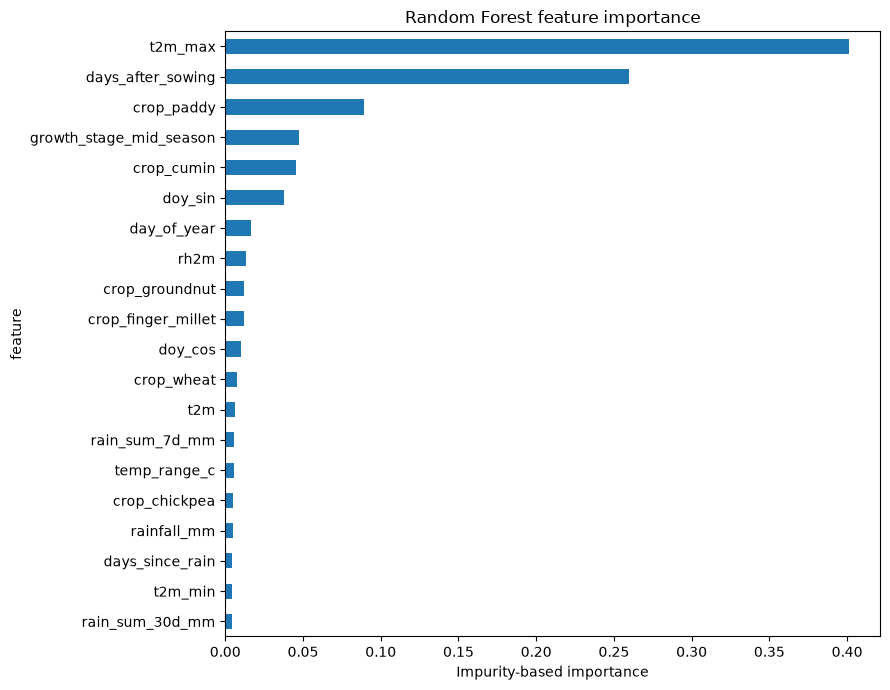

Feature importance indicates model reliance and should not be interpreted as causal agricultural influence.


In [36]:
if TARGET_READY:
    transformed_names = pipeline.named_steps['preprocess'].get_feature_names_out()
    impurity_importance = pd.DataFrame({
        'feature': transformed_names,
        'importance': pipeline.named_steps['model'].feature_importances_,
    }).sort_values('importance', ascending=False, ignore_index=True)
    display(impurity_importance.head(25))
    impurity_importance.head(20).sort_values('importance').plot.barh(
        x='feature', y='importance', legend=False, figsize=(9, 7), title='Random Forest feature importance'
    )
    plt.xlabel('Impurity-based importance')
    plt.tight_layout()
    plt.show()
    print('Feature importance indicates model reliance and should not be interpreted as causal agricultural influence.')

## 12. Error Analysis

Residual is defined as actual minus predicted. Group summaries are descriptive only and do not establish causal effects.

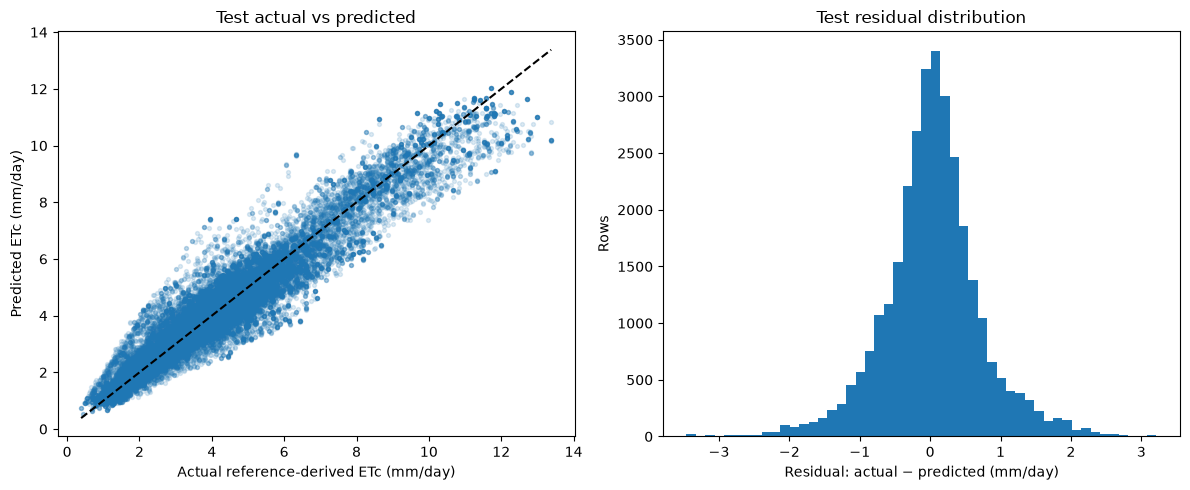

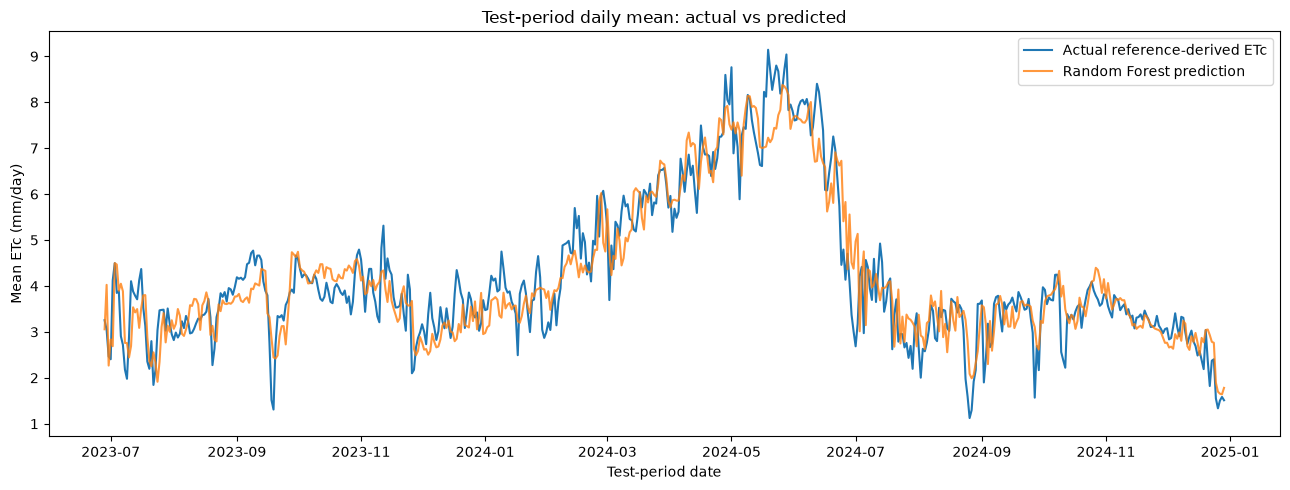

{'mean_residual_mm_day': 0.03066934903067609, 'median_absolute_error_mm_day': 0.361223223332791, 'bias_predicted_minus_actual_mm_day': -0.03066934903067609}
Error by crop (groups with at least 30 test rows; descriptive, not causal):


,rows,mae_mm_day,mean_residual_mm_day
crop,,,
cotton,5904,0.570219,0.033576
groundnut,4161,0.478384,0.026253
maize,4104,0.514715,0.039401
chickpea,3734,0.478055,0.017307
paddy,3625,0.706647,0.075800
cumin,3292,0.319487,0.015629
wheat,3292,0.517494,0.041678
finger_millet,3219,0.409818,-0.011285


Error by growth_stage (groups with at least 30 test rows; descriptive, not causal):


,rows,mae_mm_day,mean_residual_mm_day
growth_stage,,,
mid_season,11484,0.648932,0.066677
development,7628,0.470871,0.013625
late_season,7196,0.492751,-0.003078
initial,5023,0.258957,0.022575


In [37]:
if TARGET_READY:
    test_frame = partitions['test'].copy()
    test_frame['actual_mm_day'] = test_frame[tb.TARGET_COLUMN].to_numpy(dtype=float)
    test_frame['predicted_mm_day'] = partition_predictions['test']
    test_frame['residual_actual_minus_predicted_mm_day'] = test_frame['actual_mm_day'] - test_frame['predicted_mm_day']
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].scatter(test_frame['actual_mm_day'], test_frame['predicted_mm_day'], alpha=0.15, s=8)
    limits = [min(test_frame['actual_mm_day'].min(), test_frame['predicted_mm_day'].min()),
              max(test_frame['actual_mm_day'].max(), test_frame['predicted_mm_day'].max())]
    axes[0].plot(limits, limits, linestyle='--', color='black')
    axes[0].set(xlabel='Actual reference-derived ETc (mm/day)', ylabel='Predicted ETc (mm/day)', title='Test actual vs predicted')
    axes[1].hist(test_frame['residual_actual_minus_predicted_mm_day'], bins=50)
    axes[1].set(xlabel='Residual: actual − predicted (mm/day)', ylabel='Rows', title='Test residual distribution')
    plt.tight_layout()
    plt.show()
    daily = test_frame.groupby('date', as_index=False).agg(
        actual_mm_day=('actual_mm_day', 'mean'), predicted_mm_day=('predicted_mm_day', 'mean')
    )
    plt.figure(figsize=(13, 5))
    plt.plot(daily['date'], daily['actual_mm_day'], label='Actual reference-derived ETc')
    plt.plot(daily['date'], daily['predicted_mm_day'], label='Random Forest prediction', alpha=0.8)
    plt.xlabel('Test-period date')
    plt.ylabel('Mean ETc (mm/day)')
    plt.title('Test-period daily mean: actual vs predicted')
    plt.legend()
    plt.tight_layout()
    plt.show()
    print({key: test_scores[key] for key in ('mean_residual_mm_day', 'median_absolute_error_mm_day', 'bias_predicted_minus_actual_mm_day')})
    for group in ('crop', 'growth_stage'):
        counts = test_frame[group].value_counts()
        eligible = counts[counts >= 30].index
        grouped = test_frame[test_frame[group].isin(eligible)].groupby(group).agg(
            rows=('actual_mm_day', 'size'),
            mae_mm_day=('residual_actual_minus_predicted_mm_day', lambda values: float(np.mean(np.abs(values)))),
            mean_residual_mm_day=('residual_actual_minus_predicted_mm_day', 'mean'),
        ).sort_values('rows', ascending=False)
        print(f'Error by {group} (groups with at least 30 test rows; descriptive, not causal):')
        display(grouped)
    predictions_output = test_frame[['feature_date', 'date', 'crop', 'growth_stage', 'actual_mm_day', 'predicted_mm_day']].copy()
    predictions_output = predictions_output.rename(columns={'date': 'target_date'})
    residuals_output = test_frame[['feature_date', 'date', 'crop', 'growth_stage', 'residual_actual_minus_predicted_mm_day']].copy()
    residuals_output = residuals_output.rename(columns={'date': 'target_date'})
else:
    print('Error analysis unavailable because target validation did not pass.')

## 13. Save Research Outputs

Exactly six files are saved to `artifacts/research_baselines/random_forest/`. The production model registry and `artifacts/models/ACTIVE` are outside the write path.

In [38]:
if TARGET_READY:
    metrics_payload = {
        'target_name': tb.TARGET_COLUMN,
        'target_unit': 'mm/day',
        'target_provenance': 'reference_derived; not field-observed CWR',
        'forecast_horizon_days': 1,
        'xgboost_comparison_note': 'Existing XGBoost metrics use a same-day task and are not directly comparable to this one-day-ahead experiment.',
        'partitions': partition_metrics,
        'comparison': [
            {key: (None if pd.isna(value) else value) for key, value in row.items()}
            for row in comparison.to_dict(orient='records')
        ],
        'test_error_analysis': {key: test_scores[key] for key in ('mean_residual_mm_day', 'median_absolute_error_mm_day', 'bias_predicted_minus_actual_mm_day')},
    }
    metadata = rf.research_metadata(
        target_metadata=target_metadata,
        features=features,
        split=split_summary,
        n_rows=len(panel),
    )
    output_dir = rf.save_research_outputs(
        project_root=PROJECT_ROOT,
        pipeline=pipeline,
        metrics=metrics_payload,
        feature_importance=impurity_importance,
        predictions_test=predictions_output,
        residuals=residuals_output,
        metadata=metadata,
    )
    print('Saved research-only outputs:')
    for output_path in sorted(output_dir.iterdir()):
        print('-', output_path.relative_to(PROJECT_ROOT).as_posix())
    assert (PROJECT_ROOT / 'artifacts' / 'models' / 'ACTIVE').read_text(encoding='utf-8').strip() == 'reduced_input/v2'
    print('Production ACTIVE pointer remains reduced_input/v2.')
else:
    print('No metrics or model artifacts were saved because target validation did not pass.')

Saved research-only outputs:
- artifacts/research_baselines/random_forest/rf_feature_importance.csv
- artifacts/research_baselines/random_forest/rf_metadata.json
- artifacts/research_baselines/random_forest/rf_metrics.json
- artifacts/research_baselines/random_forest/rf_model.joblib
- artifacts/research_baselines/random_forest/rf_predictions_test.csv
- artifacts/research_baselines/random_forest/rf_residuals.csv
Production ACTIVE pointer remains reduced_input/v2.


## 14. Conclusion

Random Forest is a research-only conventional tree-based baseline. Reported results, if the target gate passes, quantify agreement with reference-derived ETc only and must not be described as field-observed CWR accuracy or used for farmer-facing irrigation/advisory decisions.

In [39]:
if TARGET_READY:
    print('Conclusion: research baseline trained against reference-derived ETc; not field-observed CWR.')
    print('Production integration: none. Active model and farmer-facing logic are unchanged.')
else:
    print('Random Forest training blocked: CWR target is not yet scientifically validated.')

Conclusion: research baseline trained against reference-derived ETc; not field-observed CWR.
Production integration: none. Active model and farmer-facing logic are unchanged.
